# SuperNeuroABM Tutorial 05: Event-Driven and Clocked Stepping

Every SuperNeuroABM model runs its synapses in one of two ways, chosen once when the model is
created:

```python
NeuromorphicModel(synapse_stepping="event")     # the default
NeuromorphicModel(synapse_stepping="clocked")
```

Both run the same kernels. They differ in **which synapses are stepped on each tick**: in event
stepping only the synapses that have a spike to deliver, in clocked stepping all of them. Event
stepping is what makes large networks fast, and it is also the reason SuperNeuroABM's somas,
synapses and learning rules are written the way they are. If you only use the built-in
components you never have to think about it: they work in both and give the same spikes. Once you
write your own, you need to know what event stepping asks of them, and when a model cannot use it.

1. what happens in one tick, and what each stepping skips;
2. the same network in both steppings: same spikes, different cost;
3. when a spike arrives at the next neuron;
4. what event stepping asks of your components (two demonstrations of what goes wrong otherwise);
5. a network that **needs** clocked stepping: neurons coupled by gap junctions;
6. a caveat in both steppings: the order of floating-point additions;
7. a checklist for your own components.

Files used here, next to this notebook:

| file | what it is |
|---|---|
| `customized_configs/event_driven_config.yaml` | every component this notebook creates |
| `customized_step_functions/user_customized_naive_stdp.py` | a learning rule that is right only when clocked (a counter-example, section 4) |
| `customized_step_functions/user_customized_diehl_cook_synapse.py` | tutorial 04's synapse, which reads its presynaptic spike of the same tick (section 4) |
| `customized_step_functions/user_customized_gap_junction.py` | an electrical synapse, current flowing on every tick (section 5) |

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from superneuroabm.model import NeuromorphicModel

CONFIG = Path("customized_configs/event_driven_config.yaml").resolve()
STEP_FUNC_DIR = Path("customized_step_functions").resolve()
sys.path.insert(0, str(STEP_FUNC_DIR))   # the tutorial-owned kernels are imported by module name
from user_customized_naive_stdp import user_customized_naive_stdp
from user_customized_diehl_cook_synapse import user_customized_diehl_cook_synapse
from user_customized_gap_junction import user_customized_gap_junction

DT = 1e-3   # the default tick: 1 ms
# A one-tick pulse of 20 into channel 1 (tau_syn_1 = dt in the YAML) moves a lif_soma's membrane
# by 20 mV: enough to fire it (the threshold is 15 mV above rest), and exactly once.
PULSE = {"hyperparameters": {"weight": 20.0, "channel": 1}}


def new_model(stepping, tracking=True):
    "A model on this tutorial's YAML with the given synapse stepping."
    return NeuromorphicModel(user_config=CONFIG, synapse_stepping=stepping,
                             enable_internal_states_tracking=tracking)

## 1. What happens in one tick

A tick runs the agents in priority order, with every agent of one priority finished before the
next priority starts:

| order | who runs | what it does |
|---|---|---|
| priority 0 | **every soma, every tick** | adds up what its synapses deposited in its inbox last tick (one filtered current per channel), updates its membrane, writes its spike (0 or 1) |
| priority 100 | synapses | reads its presynaptic neuron's spike of the **previous** tick, or an input spike injected for this tick; if there is one, deposits `spike * weight * scale` into one channel of the post soma's inbox |
| priority 101 | learning rules (on the synapses that have one) | reads the pre and post spikes, updates its traces and the weight |
| end of tick | the framework | hands the inbox to the somas for the next tick and clears it |

The two steppings differ only at priorities 100 and 101:

- **event**: a synapse runs only on the tick after its presynaptic neuron fired, or on a tick an
  input spike was injected into it; a learning rule runs only on the tick after its pre *or* post
  neuron fired. Every other synapse is skipped.
- **clocked**: every synapse and every learning rule runs on every tick.

Somas run on every tick either way, so a soma kernel can do anything. In a network firing at 10 Hz
with 1 ms ticks, about one synapse in a hundred has a spike to deliver on a given tick; event
stepping skips the other 99.

## 2. Same network, same spikes, different cost

A random network of `N = 5,000` neurons, each receiving `K = 200` synapses from randomly chosen
others (1,000,000 synapses, config `recurrent`: weight 0.005 into channel 0, 10 ms) and one
external input synapse (config `external`: a one-tick pulse that fires the neuron by itself), fed
with independent 10 Hz Poisson spikes. It is built with `create_from_lists` (the whole network in
one call) and run once in each stepping.

The first `simulate()` call includes construction (the input-event list, GPU buffers) and
compiling the kernel, so it is timed separately. The per-tick cost is the median of the five
1000-tick runs that follow: a single short run is easily disturbed (here the first run after the
build was sometimes twice as slow as the rest). Building the network takes up to half a minute per
stepping.

In [2]:
N, K = 5000, 200     # neurons, recurrent synapses per neuron
RATE = 0.01          # external input: probability of a spike per neuron per 1 ms tick (10 Hz)
TICKS, REPEATS = 1000, 5   # timed as five runs of 1000 ticks
TOTAL_TICKS = 1 + TICKS * REPEATS


def random_network(stepping, seed=0):
    rng = np.random.default_rng(seed)
    model = new_model(stepping, tracking=False)
    post = np.repeat(np.arange(N), K)
    pre = rng.integers(0, N - 1, size=N * K)
    pre = pre + (pre >= post)                       # no neuron synapses onto itself
    synapses = [{"id": N + j, "pre": p, "post": q, "config": "recurrent"}
                for j, (p, q) in enumerate(zip(pre.tolist(), post.tolist()))]
    first_input = N + N * K
    synapses += [{"id": first_input + i, "pre": -1, "post": i, "config": "external"} for i in range(N)]
    model.create_from_lists(somas=[{"id": i} for i in range(N)], synapses=synapses)
    model.setup()
    ticks, neurons = np.nonzero(rng.random((TOTAL_TICKS, N)) < RATE)
    model.add_spikes(first_input + neurons, ticks, 1.0)
    return model


ms_per_tick, spikes = {}, {}
for stepping in ("event", "clocked"):
    model = random_network(stepping)
    t0 = time.perf_counter()
    model.simulate(ticks=1)
    first = time.perf_counter() - t0
    runs = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        model.simulate(ticks=TICKS)
        runs.append(1e3 * (time.perf_counter() - t0) / TICKS)
    ms_per_tick[stepping] = float(np.median(runs))
    spikes[stepping] = model.get_all_spike_times()   # each simulate() call records its own spikes: the last run's
    n = sum(len(s) for s in spikes[stepping].values())
    print(f"{stepping:8s} first tick {first:5.2f} s, then {ms_per_tick[stepping]:.3f} ms/tick "
          f"(median of {REPEATS} runs of {TICKS} ticks); last run {n:,} spikes ({n / N / (TICKS * DT):.1f} Hz per neuron)")
    del model

print(f"\nsame spikes in both steppings (last run, every neuron): {spikes['event'] == spikes['clocked']}")
print(f"event stepping is {ms_per_tick['clocked'] / ms_per_tick['event']:.1f}x faster per tick")

event    first tick  3.33 s, then 0.033 ms/tick (median of 5 runs of 1000 ticks); last run 48,983 spikes (9.8 Hz per neuron)
clocked  first tick  0.60 s, then 0.144 ms/tick (median of 5 runs of 1000 ticks); last run 48,983 spikes (9.8 Hz per neuron)

same spikes in both steppings (last run, every neuron): True
event stepping is 4.3x faster per tick


The spike trains are identical, spike for spike, and event stepping is several times faster per
tick. The gap grows with the number of synapses per neuron and shrinks with the firing rate:
event stepping does work in proportion to spikes times fan-out, clocked stepping in proportion
to synapses. Somas cost the same in both, since they run on every tick either way. The exact ratio
also depends on the machine and on what else runs on it: on the shared node this notebook was
written on, the same cell measured between 2x and 4.4x.

The first-tick times are not a property of the stepping: the first `simulate()` call compiles the
kernel when it has not been compiled before (the result is cached), so whichever model runs first
in a fresh session can take seconds. With the cache warm, both first ticks take a fraction of a
second.

## 3. When a spike arrives at the next neuron

A chain: an input spike at tick 10 into neuron A, then A → B → C, every synapse a one-tick pulse
strong enough to fire its target.

In [3]:
for stepping in ("event", "clocked"):
    model = new_model(stepping)
    a, b, c = (model.create_soma(breed="lif_soma", config_name="config_0") for _ in range(3))
    drive = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=a,
                                 config_name="config_0", overrides=PULSE)
    model.create_synapse(breed="delivery_synapse", pre_soma_id=a, post_soma_id=b,
                         config_name="config_0", overrides=PULSE)
    model.create_synapse(breed="delivery_synapse", pre_soma_id=b, post_soma_id=c,
                         config_name="config_0", overrides=PULSE)
    model.setup()
    model.add_spike(drive, tick=10, value=1.0)
    model.simulate(ticks=30)
    print(f"{stepping:8s} input at tick 10 -> A fires at {model.get_spike_times(a)}, "
          f"B at {model.get_spike_times(b)}, C at {model.get_spike_times(c)}")

event    input at tick 10 -> A fires at [11], B at [13], C at [15]
clocked  input at tick 10 -> A fires at [11], B at [13], C at [15]


The same in both steppings:

- **input → soma, 1 tick.** The injected spike is delivered by its synapse at tick 10; A reads its
  inbox and fires at tick 11.
- **soma → soma, 2 ticks.** A fires at 11. Its synapse runs at tick 12 (in event stepping, *because*
  A fired at 11) and reads A's spike of tick 11; B reads the deposit and fires at 13.

The built-in synapse always reads the presynaptic spike of the previous tick, in both steppings:
that is what makes them interchangeable. The price is a fixed delay of two ticks per connection,
so pick `dt` with that in mind (2 ms per hop at the default 1 ms).

## 4. What event stepping asks of your components

Three rules follow from "a synapse runs only on the tick after its pre fired":

1. **A synapse keeps no state that changes between spikes.** Nothing would update it. That is why
   the synaptic current and its time constant live on the soma, in its inbox channels, and the
   synapse only says *when* and *how much* (tutorial 02, section 6, rebuilds the weighted,
   single-exponential and double-exponential synapses that way). A custom synapse that respects
   this is registered with `register_synapse_type(..., event_capable=True)`.
2. **A learning rule catches up when it wakes.** Its traces must decay over all the ticks since it
   last ran, not by one tick's factor per run.
3. **A synapse reads the presynaptic spike of the previous tick.** When it is woken, that is the
   spike that woke it.

`event_capable=True` is a promise the model cannot check. The two demonstrations below break rules
2 and 3 on purpose and compare against clocked stepping, where every component runs every tick and
the promise does not matter. **Running a small network in both steppings and comparing the spikes
is also the test for your own components.**

### A learning rule that does not catch up

`user_customized_naive_stdp` is the built-in `exp_pair_wise_stdp` with one line changed: each time it
runs, it decays its traces by one tick's factor, `1 - dt/tau`. The built-in rule decays them by
`trace_decay(dt, tau, n) = (1 - dt/tau)^n` over the `n` ticks since it last ran, and records the
tick it ran in `learning_internal_states[3]` (`last_tick` in the YAML).

The experiment is the STDP window: 40 independent neuron pairs, the pre neuron forced to fire at
tick 31 and the post neuron `d` ticks later (`d` from -20 to 20). Each pair has one plastic synapse
of weight 0, so it never changes when the post neuron fires and its weight after the run is the
learned change `dW`. Both rules, both steppings.

rule                         stepping  dW at d = +1      +5       +20
exp_pair_wise_stdp           clocked   +0.00450  +0.00295  +0.00061
exp_pair_wise_stdp           event     +0.00450  +0.00295  +0.00061
user_customized_naive_stdp   clocked   +0.00450  +0.00295  +0.00061
user_customized_naive_stdp   event     +0.00450  +0.00450  +0.00450
built-in rule, event vs clocked: largest relative difference over all d 2.2e-07


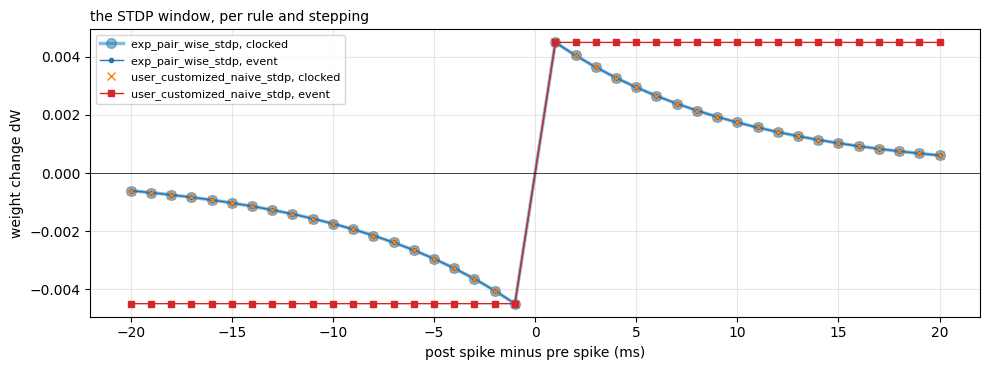

In [4]:
DELTAS = [d for d in range(-20, 21) if d != 0]   # the post spike d ticks after the pre spike


def stdp_window(rule, stepping):
    "dW of one plastic synapse per pairing offset d."
    model = new_model(stepping, tracking=False)
    rule_hyperparameters = {}
    if rule == "user_customized_naive_stdp":
        rule_id = model.register_learning_rule(
            step_func=user_customized_naive_stdp,
            step_func_path=STEP_FUNC_DIR / "user_customized_naive_stdp.py",
            event_capable=True,       # a FALSE promise: this rule does not catch up
        )
        rule_hyperparameters = {"stdp_type": float(rule_id)}
    plastic, drives = [], []
    for d in DELTAS:
        pre = model.create_soma(breed="lif_soma", config_name="config_0")
        post = model.create_soma(breed="lif_soma", config_name="config_0")
        drive_pre = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=pre,
                                         config_name="config_0", overrides=PULSE)
        drive_post = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=post,
                                          config_name="config_0", overrides=PULSE)
        plastic.append(model.create_synapse(
            breed="delivery_synapse", pre_soma_id=pre, post_soma_id=post, config_name="config_0",
            learning_rule=rule, learning_rule_config="default",
            overrides={"hyperparameters": {"weight": 0.0, "channel": 1},
                       "learning_hyperparameters": rule_hyperparameters}))
        drives.append((drive_pre, drive_post, d))
    model.setup()
    for drive_pre, drive_post, d in drives:
        model.add_spike(drive_pre, tick=30, value=1.0)
        model.add_spike(drive_post, tick=30 + d, value=1.0)
    model.simulate(ticks=80)
    return np.array([model.get_hyperparameters(s)["weight"] for s in plastic])


windows = {(rule, stepping): stdp_window(rule, stepping)
           for rule in ("exp_pair_wise_stdp", "user_customized_naive_stdp")
           for stepping in ("clocked", "event")}

at = [DELTAS.index(d) for d in (1, 5, 20)]
print(f"{'rule':28s} {'stepping':8s}  dW at d = +1      +5       +20")
for (rule, stepping), dw in windows.items():
    print(f"{rule:28s} {stepping:8s}  {dw[at[0]]:+.5f}  {dw[at[1]]:+.5f}  {dw[at[2]]:+.5f}")
builtin_event, builtin_clocked = windows[("exp_pair_wise_stdp", "event")], windows[("exp_pair_wise_stdp", "clocked")]
print(f"built-in rule, event vs clocked: largest relative difference over all d "
      f"{(np.abs(builtin_event - builtin_clocked) / np.abs(builtin_clocked)).max():.1e}")

fig, ax = plt.subplots(figsize=(10, 3.8))
style = {("exp_pair_wise_stdp", "clocked"): dict(color="C0", marker="o", ms=7, lw=2.5, alpha=0.5),
         ("exp_pair_wise_stdp", "event"): dict(color="C0", marker=".", lw=1),
         ("user_customized_naive_stdp", "clocked"): dict(color="C1", marker="x", lw=0),
         ("user_customized_naive_stdp", "event"): dict(color="C3", marker="s", ms=4, lw=1)}
for key, dw in windows.items():
    ax.plot(DELTAS, dw, label=f"{key[0]}, {key[1]}", **style[key])
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("post spike minus pre spike (ms)")
ax.set_ylabel("weight change dW")
ax.set_title("the STDP window, per rule and stepping", loc="left", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The built-in rule draws the exponential STDP window, the same in both steppings up to float32
rounding (event stepping computes `(1 - dt/tau)^n` in one power, clocked stepping multiplies by
`1 - dt/tau` on each of the `n` ticks). The naive rule
is right when clocked (its crosses sit on the built-in curve) and flat when event-driven: it runs
once after the pre spike and once after the post spike, decays by one tick in between whatever the
gap, so every pairing looks like `d = ±1`. Nothing fails or warns; the model learns something else.

How to write a rule that catches up (the built-in rules, and the custom ones in tutorials 01 and
03, all do this):

```python
n = t_current - int(learning_internal_states[agent_index][3])   # ticks since the last run
if n < 1:
    n = 1
pre_trace = pre_trace * trace_decay(dt, tau_pre, n) + pre_spike * a_pre
...
learning_internal_states[agent_index][3] = 1.0 * t_current      # remember this run
```

`trace_decay` is in `superneuroabm.step_functions.synapse.util`; with `n = 1` it is the single
factor `1 - dt/tau`, so the rule is unchanged when clocked.

### A synapse that reads the spike of the same tick

Tutorial 04's synapse reads its presynaptic neuron's spike of the **current** tick (somas run before
synapses, so it is there), which makes a connection one tick long instead of two: the authors'
network needs that timing. Registered as event-capable, which it is not, it is woken on the tick
*after* the spike and finds no spike in the current tick's slot.

In [5]:
for stepping in ("clocked", "event"):
    model = new_model(stepping)
    model.register_synapse_type(
        name="user_customized_diehl_cook_synapse",
        step_func=user_customized_diehl_cook_synapse,
        step_func_path=STEP_FUNC_DIR / "user_customized_diehl_cook_synapse.py",
        event_capable=(stepping == "event"),   # in event stepping: a FALSE promise
    )
    a = model.create_soma(breed="lif_soma", config_name="config_0")
    b = model.create_soma(breed="lif_soma", config_name="config_0")
    drive = model.create_synapse(breed="delivery_synapse", pre_soma_id=-1, post_soma_id=a,
                                 config_name="config_0", overrides=PULSE)
    model.create_synapse(breed="user_customized_diehl_cook_synapse", pre_soma_id=a, post_soma_id=b,
                         config_name="config_0")
    model.setup()
    for t in (10, 30, 50):
        model.add_spike(drive, tick=t, value=1.0)
    model.simulate(ticks=70)
    print(f"{stepping:8s} A fires at {model.get_spike_times(a)}, B at {model.get_spike_times(b)}")

clocked  A fires at [11, 31, 51], B at [12, 32, 52]
event    A fires at [11, 31, 51], B at []


Clocked, B fires one tick after A, as intended. Event-driven, B never fires: every spike is lost,
silently. A component that needs the same-tick spike needs clocked stepping, which is what
tutorial 04 uses.

## 5. A network that needs clocked stepping: gap junctions

Some synapses are not driven by spikes at all. A **gap junction** (electrical synapse) is a channel
between two cells' membranes: on every tick, current flows from the more depolarised cell to the
other in proportion to the voltage difference,

$$I = g\,(v_\text{pre} - v_\text{post}),$$

whether or not either cell fires. Gap junctions couple inhibitory interneurons in cortex and the
cells of the inferior olive, often next to ordinary chemical synapses. There is no event to wake
such a synapse, so it must run on every tick: `user_customized_gap_junction` reads both somas'
membrane potentials and deposits `I` into a one-tick channel of the post soma. It is registered
**without** `event_capable`, and event stepping refuses it.

The network: four cells in a chain, A - B - C - D, each neighbouring pair joined by a junction
(`g = 0.1`; two synapse agents per junction, one each way). Only A receives input, a constant
current that makes it fire on its own; B, C and D get nothing but what flows through the junctions.
Three runs: without junctions; with junctions, clocked; and with junctions forced into event
stepping by a false `event_capable=True`.

event stepping refuses the gap junction:
  synapse_stepping='event': synapse type 'user_customized_gap_junction' must be event_capable (no per-tick state; stepped only on the tick after its pre fired) 

no junctions                      A fires 18 times; mean v over ticks 50-99 of A, B, C, D: [-51.4 -60.  -60.  -60. ]
junctions, clocked                A fires 16 times; mean v over ticks 50-99 of A, B, C, D: [-51.5 -56.8 -58.7 -59.4]
junctions, event (false promise)  A fires 18 times; mean v over ticks 50-99 of A, B, C, D: [-51.4 -59.4 -60.  -60. ]


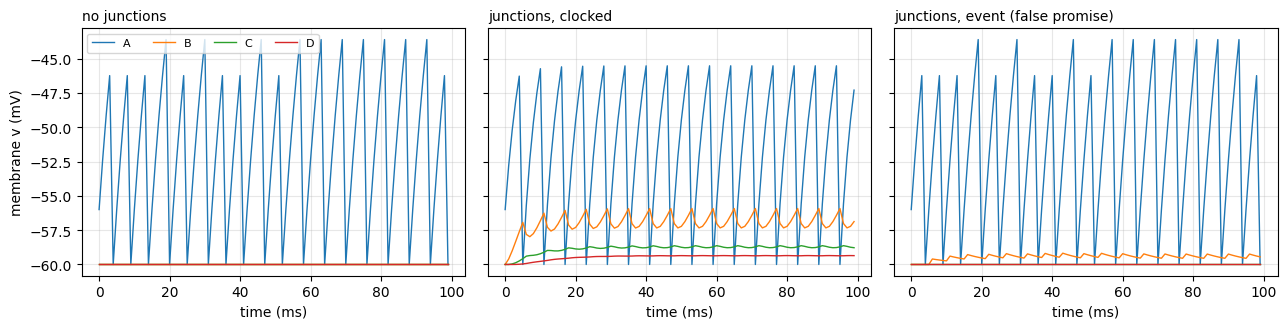


With gap junctions the whole model runs clocked, chemical synapses included: section 2's network would cost 0.144 instead of 0.033 ms per tick.


In [6]:
try:
    new_model("event").register_synapse_type(
        name="user_customized_gap_junction", step_func=user_customized_gap_junction,
        step_func_path=STEP_FUNC_DIR / "user_customized_gap_junction.py")
except ValueError as err:
    print("event stepping refuses the gap junction:\n ", err, "\n")


def gap_junction_chain(stepping, junctions, event_capable=False, ticks=100):
    "Membrane potentials (4 x ticks) of the chain A - B - C - D, and A's spike ticks."
    model = new_model(stepping)
    model.register_synapse_type(
        name="user_customized_gap_junction", step_func=user_customized_gap_junction,
        step_func_path=STEP_FUNC_DIR / "user_customized_gap_junction.py", event_capable=event_capable)
    cells = [model.create_soma(breed="lif_soma", config_name="config_0",
                               overrides={"hyperparameters": {"I_in": 4e-5 if i == 0 else 0.0}})
             for i in range(4)]                       # only A is driven
    if junctions:
        for x, y in zip(cells[:-1], cells[1:]):
            for pre, post in ((x, y), (y, x)):        # one junction = one synapse each way
                model.create_synapse(breed="user_customized_gap_junction", pre_soma_id=pre,
                                     post_soma_id=post, config_name="config_0")
    model.setup()
    model.simulate(ticks=ticks)
    v = np.array([np.array(model.get_internal_states_history(c), dtype=np.float64)[:, 0] for c in cells])
    return v, model.get_spike_times(cells[0])


runs = {
    "no junctions": gap_junction_chain("clocked", junctions=False),
    "junctions, clocked": gap_junction_chain("clocked", junctions=True),
    "junctions, event (false promise)": gap_junction_chain("event", junctions=True, event_capable=True),
}
for label, (v, a_spikes) in runs.items():
    print(f"{label:33s} A fires {len(a_spikes):2d} times; mean v over ticks 50-99 of A, B, C, D:",
          np.round(v[:, 50:].mean(axis=1), 1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (label, (v, a_spikes)) in zip(axes, runs.items()):
    t = np.arange(v.shape[1]) * DT * 1e3
    for i, name in enumerate("ABCD"):
        ax.plot(t, v[i], lw=1, label=name)
    ax.set_title(label, loc="left", fontsize=10)
    ax.set_xlabel("time (ms)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("membrane v (mV)")
axes[0].legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

print(f"\nWith gap junctions the whole model runs clocked, chemical synapses included: section 2's "
      f"network would cost {ms_per_tick['clocked']:.3f} instead of {ms_per_tick['event']:.3f} ms per tick.")

Without junctions only A moves. With them, clocked, A's depolarisation spreads down the chain and
fades with distance, B's membrane follows A's sawtooth, and A fires a little less because it loses
current to its neighbours; B, C and D never fire, so in event stepping their junctions would never
run. Forced into event stepping, the junctions run only on the tick after A fires, when A has just
reset, and the coupling is almost gone.

**A model with even one component like this runs clocked as a whole**: `synapse_stepping` is one
setting for the model, so every chemical synapse is stepped on every tick too. Other components
in the same position:

- a synapse with its own current and time constant per synapse (the former `single_exp_synapse`
  kept as it was, rather than moved to the soma);
- a synapse whose effect depends on the post membrane on every tick (a per-synapse NMDA-type
  voltage dependence);
- a learning rule driven by the membrane potential rather than by spikes (the voltage-based rule
  of Clopath et al., 2010);
- a synapse that needs the presynaptic spike of the same tick (section 4, tutorial 04).

On several GPUs the gap junction also needs `model.set_property_neighbor_visible("internal_states",
True)` before `setup()`: by default only a soma's spike is sent to the ranks that hold its synapses.

## 6. A caveat in both steppings: the order of additions

Synapses deposit into a soma's inbox with atomic additions, and the order in which the GPU threads
of one tick add up is not fixed. Floating-point addition is not associative, so when the deposits
differ in size the sum can differ in its last bit from one run to the next. In section 2 every
recurrent synapse had the same weight, where order cannot matter, and both steppings agreed to the
bit. Below, a smaller network where every synapse has its own weight, run twice event-driven and
once clocked.

In [7]:
def jittered_network(stepping, n=2000, k=100, ticks=300, seed=0):
    "Final membrane potentials and spikes of a random network with per-synapse weights."
    rng = np.random.default_rng(seed)
    model = new_model(stepping, tracking=False)
    post = np.repeat(np.arange(n), k)
    pre = rng.integers(0, n - 1, size=n * k)
    pre = pre + (pre >= post)
    weights = 0.05 * (1 + 0.2 * rng.standard_normal(n * k))     # every synapse its own weight
    synapses = [{"id": n + j, "pre": p, "post": q, "config": "recurrent",
                 "overrides": {"hyperparameters": {"weight": w}}}
                for j, (p, q, w) in enumerate(zip(pre.tolist(), post.tolist(), weights.tolist()))]
    synapses += [{"id": n + n * k + i, "pre": -1, "post": i, "config": "external"} for i in range(n)]
    model.create_from_lists(somas=[{"id": i} for i in range(n)], synapses=synapses)
    model.setup()
    t, who = np.nonzero(rng.random((ticks + 1, n)) < RATE)
    model.add_spikes(n + n * k + who, t, 1.0)
    model.simulate(ticks=ticks)
    v = model.get_breed_data("lif_soma", "internal_states")[:, 0].astype(np.float64)
    return model.get_all_spike_times(), v


first, second, clocked = (jittered_network(s) for s in ("event", "event", "clocked"))
for label, (sa, va), (sb, vb) in (("event, run 1 vs run 2", first, second),
                                  ("event vs clocked     ", first, clocked)):
    dv = np.abs(va - vb)
    print(f"{label}: spikes identical {sa == sb}; {int((dv > 0).sum())} of {len(dv)} membranes "
          f"differ, by at most {dv.max():.1e} mV")

event, run 1 vs run 2: spikes identical True; 10 of 2000 membranes differ, by at most 3.8e-06 mV
event vs clocked     : spikes identical True; 16 of 2000 membranes differ, by at most 3.8e-06 mV


The spikes agree, and a few membranes differ in the last bits of a float32. Over a long run a
chaotic network amplifies such differences until individual spike times diverge, while the
statistics (rates, correlations) stay the same. NEST GPU and GeNN have the same property. Compare
runs by their statistics, or by spikes on short runs and small test networks, which is how the
section 4 comparisons above work.

## 7. Checklist for your own components

| your component | write it | register it | stepping |
|---|---|---|---|
| a soma, any dynamics | anything; read the inbox with `synaptic_current` or `read_synaptic_input` | `register_soma_type` | either |
| a synapse that delivers when its pre fires | read the spike with `get_soma_spike`, deposit with `deliver_synaptic_current` | `register_synapse_type(..., event_capable=True)` | event |
| a synapse whose effect has a time course (exponential, double exponential, conductance) | put the time course on the soma: one inbox channel per time constant (tutorial 02, section 6) | `event_capable=True` | event |
| a learning rule driven by pre and post spikes | traces decayed with `trace_decay(dt, tau, t - last_tick)`, `last_tick` kept at `learning_internal_states[3]` | `register_learning_rule(..., event_capable=True)` | event |
| a synapse or rule that changes between spikes (gap junction, per-synapse current, voltage-based plasticity) | its own state, updated every tick | without `event_capable` | **clocked**, the whole model |
| a connection one tick long | read `output_spikes_tensor[pre][t % 2]` | without `event_capable` | **clocked**, the whole model |

And the test for any custom component: build a small network with it, run it once with
`synapse_stepping="event"` and once with `"clocked"`, and compare the spikes.

Where to look next: tutorial 02 (every built-in component, and the former synapse types rebuilt on
the soma's channels), tutorial 06 (how input reaches a soma, and when to write a synapse or a soma
step function), tutorial 03 (a learning network that runs event-driven), tutorial 04 (one
that needs clocked stepping for its timing), and `docs/CUSTOM_COMPONENTS.md` for the kernel
signatures. The design and the measurements behind event stepping are in
`docs/EVENT_DRIVEN_NOTES.md`.